# Symbolic Regression for Reaction-Rate Equation Discovery

## PySR Baseline, Equation Simplification, and Noise Reduction

This notebook evaluates PySR on six known reaction-rate laws, develops a data-driven equation simplifier, and compares raw numerical differentiation with Savitzky–Golay preprocessing.

The generated dataset from Notebook 1 is used throughout. In the noisy-data experiments, only measured concentrations and time are used for preprocessing and model training. Clean concentrations and exact rates are retained solely for retrospective evaluation.

## 1. Environment Setup

Install the required packages once in the active notebook environment if they are not already installed:

```python
%pip install pysr numpy pandas matplotlib scipy sympy scikit-learn
```

PySR may compile its Julia backend during its first model fit.

## 2. Import Libraries

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import sympy as sp

from itertools import combinations
from pathlib import Path
from scipy.signal import savgol_filter
from scipy.optimize import least_squares
from pysr import PySRRegressor
from sklearn.metrics import mean_squared_error, mean_absolute_error

## 3. Load and Inspect the Generated Dataset

In [2]:
data_dir = Path("reaction_data")
dataset_path = data_dir / "reaction_dataset.csv"
parameters_path = data_dir / "rate_law_parameters.csv"

if not dataset_path.exists():
    raise FileNotFoundError(f"Dataset not found: {dataset_path.resolve()}")
if not parameters_path.exists():
    raise FileNotFoundError(f"Parameter file not found: {parameters_path.resolve()}")

df = pd.read_csv(dataset_path)
parameters_df = pd.read_csv(parameters_path)

required_columns = {
    "reaction", "time_min", "noise_level", "replicate",
    "CA_true", "CA_observed"
}
missing_columns = required_columns - set(df.columns)
if missing_columns:
    raise ValueError(f"Missing dataset columns: {sorted(missing_columns)}")

print("Dataset shape:", df.shape)
print("Available reactions:", sorted(df["reaction"].unique()))
print("Noise levels:", sorted(df["noise_level"].unique()))
print("Replicates:", sorted(df["replicate"].unique()))
print("Missing values:\n", df.isnull().sum())

display(df.head())
display(parameters_df)

Dataset shape: (11616, 6)
Available reactions: ['First_Order', 'Fourth_Order', 'Fractional_Order', 'Saturation', 'Second_Order', 'Zero_Order']
Noise levels: [np.float64(0.0), np.float64(0.01), np.float64(0.03), np.float64(0.05)]
Replicates: [np.int64(0), np.int64(1), np.int64(2), np.int64(3), np.int64(4), np.int64(5)]
Missing values:
 reaction       0
time_min       0
noise_level    0
replicate      0
CA_true        0
CA_observed    0
dtype: int64


,reaction,time_min,noise_level,replicate,CA_true,CA_observed
0,First_Order,0.00,0.0,0,0.050000,0.050000
1,First_Order,0.25,0.0,0,0.048765,0.048765
2,First_Order,0.50,0.0,0,0.047561,0.047561
3,First_Order,0.75,0.0,0,0.046387,0.046387
4,First_Order,1.00,0.0,0,0.045242,0.045242


,reaction,k,Vmax,K
0,First_Order,0.100000,NaN,NaN
1,Second_Order,2.000000,NaN,NaN
2,Fractional_Order,0.447214,NaN,NaN
3,Saturation,NaN,0.007,0.02
4,Fourth_Order,800.000000,NaN,NaN
5,Zero_Order,0.005000,NaN,NaN


## 4. Define the Ground-Truth Rate Laws

The benchmark systems use the following disappearance-rate expressions, where \(r=-dC_A/dt\):

| Reaction | Rate law |
|---|---|
| First order | \(r=kC_A\) |
| Second order | \(r=kC_A^2\) |
| Fractional order | \(r=kC_A^{1.5}\) |
| Saturation | \(r=V_{\max}C_A/(K+C_A)\) |
| Fourth order | \(r=kC_A^4\) |
| Zero order | \(r=k\) |

In [3]:
def calculate_rate(CA, reaction, params):
    if reaction == "First_Order":
        return params["k"] * CA
    elif reaction == "Second_Order":
        return params["k"] * CA**2
    elif reaction == "Fractional_Order":
        return params["k"] * CA**1.5
    elif reaction == "Saturation":
        return params["Vmax"] * CA / (params["K"] + CA)
    elif reaction == "Fourth_Order":
        return params["k"] * CA**4
    elif reaction == "Zero_Order":
        return params["k"]
    else:
        raise ValueError(f"Unknown reaction: {reaction}")


parameter_lookup = parameters_df.set_index("reaction").to_dict("index")

## 5. Construct the Clean Ground-Truth Dataset

The clean data provide an ideal-condition baseline. Exact rates are calculated from the known benchmark equations. Observations after depletion are excluded from the zero-order system because the zero-order law no longer applies once reactant A is exhausted.

In [4]:
df_clean = df.loc[df["noise_level"] == 0].copy()

df_clean["rate_true"] = df_clean.apply(
    lambda row: calculate_rate(
        row["CA_true"],
        row["reaction"],
        parameter_lookup[row["reaction"]]
    ),
    axis=1
)

df_clean = df_clean.loc[
    ~(
        (df_clean["reaction"] == "Zero_Order")
        & (df_clean["CA_true"] <= 0)
    )
].copy()

df_clean = df_clean.sort_values(
    ["reaction", "time_min"]
).reset_index(drop=True)

print("Clean dataset shape:", df_clean.shape)
display(df_clean.head())
display(df_clean.groupby("reaction").size().rename("observations"))

Clean dataset shape: (645, 7)


,reaction,time_min,noise_level,replicate,CA_true,CA_observed,rate_true
0,First_Order,0.00,0.0,0,0.050000,0.050000,0.005000
1,First_Order,0.25,0.0,0,0.048765,0.048765,0.004877
2,First_Order,0.50,0.0,0,0.047561,0.047561,0.004756
3,First_Order,0.75,0.0,0,0.046387,0.046387,0.004639
4,First_Order,1.00,0.0,0,0.045242,0.045242,0.004524


reaction
First_Order         121
Fourth_Order        121
Fractional_Order    121
Saturation          121
Second_Order        121
Zero_Order           40
Name: observations, dtype: int64

## 6. Visualize the Ground-Truth Rate Laws

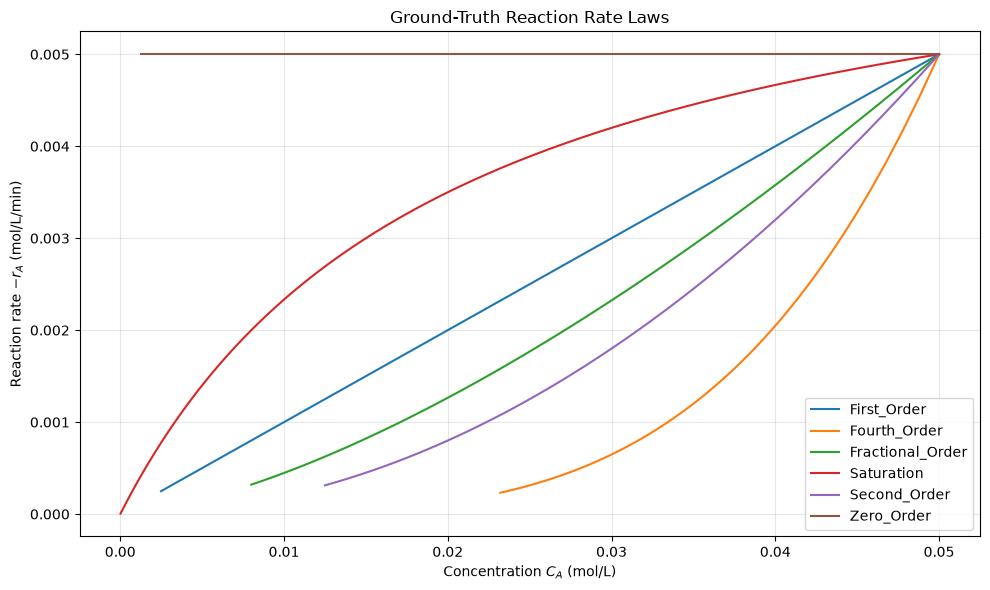

In [5]:
plt.figure(figsize=(10, 6))

for reaction, subset in df_clean.groupby("reaction"):
    subset = subset.sort_values("CA_true")
    plt.plot(
        subset["CA_true"],
        subset["rate_true"],
        label=reaction
    )

plt.xlabel("Concentration $C_A$ (mol/L)")
plt.ylabel("Reaction rate $-r_A$ (mol/L/min)")
plt.title("Ground-Truth Reaction Rate Laws")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

## 7. Configure PySR

A separate symbolic-regression model is trained for each reaction. The operator set includes arithmetic operations and powers. The power constraint limits the complexity of the base and exponent expressions searched by PySR.

In [6]:
def create_pysr_model(verbosity=0):
    return PySRRegressor(
        niterations=100,
        populations=15,
        population_size=33,
        maxsize=20,
        binary_operators=["+", "-", "*", "/", "^"],
        constraints={"^": (-1, 1)},
        model_selection="best",
        verbosity=verbosity
    )

## 8. Run the Clean-Data PySR Baseline

For each reaction, the input is the true concentration \(C_A\) and the target is the exact rate calculated from the known rate law. This is an ideal-condition equation-recovery experiment, not a noisy experimental test.

In [7]:
models = {}

for reaction, subset in df_clean.groupby("reaction"):
    X = subset[["CA_true"]].to_numpy(dtype=float)
    y = subset["rate_true"].to_numpy(dtype=float)

    model = create_pysr_model(verbosity=0)
    model.fit(X, y)
    models[reaction] = model

    print(f"Completed: {reaction}")

Completed: First_Order
Completed: Fourth_Order
Completed: Fractional_Order
Completed: Saturation
Completed: Second_Order
Completed: Zero_Order


## 9. Summarize the Baseline PySR Equations

In [8]:
baseline_results = []

for reaction, model in models.items():
    equations = model.equations_
    best_idx = equations["loss"].idxmin()
    best = equations.loc[best_idx]

    baseline_results.append({
        "Reaction": reaction,
        "Lowest-loss equation": best["equation"],
        "PySR loss": best["loss"],
        "Complexity": best["complexity"],
        "Score": best["score"]
    })

baseline_df = pd.DataFrame(baseline_results)
display(baseline_df)

,Reaction,Lowest-loss equation,PySR loss,Complexity,Score
0,First_Order,((x0 / (x0 * 0.1)) * 0.010000001) * x0,5.957232e-21,9,0.057484
1,Fourth_Order,(x0 * (x0 * ((x0 * 0.5173968) * x0))) * 1546.202,1.720317e-20,11,12.047945
2,Fractional_Order,(x0 - ((x0 * x0) + 3.4421673e-6)) * (((x0 ^ 0....,1.666517e-13,17,0.125724
3,Saturation,(0.64015144 - ((x0 ^ 0.19128197) - (((x0 ^ 0.2...,7.045903e-10,15,0.024267
4,Second_Order,((x0 + x0) / (x0 * x0)) * ((x0 * ((x0 * x0) * ...,5.159201e-21,17,0.070219
5,Zero_Order,0.005,0.000000e+00,1,0.000000


## 10. Equation Simplification

PySR can return several candidate equations, including expressions that are unnecessarily complicated. The simplifier generates algebraically equivalent forms, additive-term subsets, and rational candidates formed from numerator and denominator subsets. It then refits multiplicative coefficients by least squares.

The ranking criterion contains two parts:

1. A BIC-style fit term based on the residual sum of squares and the rank of the fitted design matrix.
2. A symbolic-complexity penalty based on the number of operations in the fitted expression.

The combined `Selection Score` is a BIC-inspired complexity score, not classical BIC. Its purpose is to rank candidate expressions by fit and symbolic simplicity. It must be checked on held-out data before a final kinetic equation is accepted.

In [9]:
x0 = sp.symbols("x0")


def _subset_expressions(terms, max_terms=6):
    terms = list(terms)
    if not terms:
        return []
    if len(terms) > max_terms:
        return [sp.Add(*terms)] + terms

    return [
        sp.Add(*subset)
        for size in range(1, len(terms) + 1)
        for subset in combinations(terms, size)
    ]


def _evaluate_expression(expression, X):
    function = sp.lambdify(x0, expression, modules="numpy")
    with np.errstate(divide="ignore", invalid="ignore", over="ignore"):
        values = np.asarray(function(X), dtype=float)
    return np.broadcast_to(values, X.shape)


def _normalize_linear_denominator(expression):
    numerator, denominator = sp.fraction(sp.together(expression))

    if denominator == 1:
        return expression

    try:
        denominator_poly = sp.Poly(denominator, x0)
        numerator_poly = sp.Poly(numerator, x0)

        if denominator_poly.degree() != 1:
            return expression

        leading_coefficient = denominator_poly.LC()
        if not leading_coefficient.is_number or leading_coefficient == 0:
            return expression

        normalized_numerator = sp.Poly(
            numerator_poly.as_expr() / leading_coefficient, x0
        ).as_expr()
        normalized_denominator = sp.Poly(
            denominator_poly.as_expr() / leading_coefficient, x0
        ).as_expr()

        return sp.Mul(
            normalized_numerator,
            sp.Pow(normalized_denominator, -1, evaluate=False),
            evaluate=False
        )

    except (sp.PolynomialError, ValueError, TypeError):
        return expression


def _fit_candidate(candidate, X, y):
    candidate_terms = sp.Add.make_args(candidate)

    if len(candidate_terms) == 1:
        _, base = candidate_terms[0].as_coeff_Mul()
        float_atoms = sorted(base.atoms(sp.Float), key=sp.default_sort_key)

        if float_atoms:
            parameter_symbols = sp.symbols(f"p0:{len(float_atoms)}")
            template = base.xreplace(dict(zip(float_atoms, parameter_symbols)))
            function = sp.lambdify(
                (x0, *parameter_symbols),
                template,
                modules="numpy"
            )
            initial_values = np.array([float(value) for value in float_atoms])
            basis_values = np.asarray(
                function(X, *initial_values), dtype=float
            )
            basis_values = np.broadcast_to(basis_values, X.shape)

            if not np.all(np.isfinite(basis_values)):
                return None

            denominator = max(
                float(np.dot(basis_values, basis_values)),
                np.finfo(float).tiny
            )
            initial_scale = float(np.dot(basis_values, y) / denominator)
            target_scale = max(float(np.sqrt(np.mean(y**2))), np.finfo(float).tiny)

            def residual(parameters):
                with np.errstate(divide="ignore", invalid="ignore", over="ignore"):
                    predictions = parameters[0] * np.asarray(
                        function(X, *parameters[1:]), dtype=float
                    )
                predictions = np.broadcast_to(predictions, X.shape)
                if not np.all(np.isfinite(predictions)):
                    return np.full_like(y, 1e6)
                return (predictions - y) / target_scale

            optimum = least_squares(
                residual,
                np.r_[initial_scale, initial_values],
                max_nfev=1000
            )

            fitted_base = template.xreplace({
                parameter: sp.Float(float(value), 12)
                for parameter, value in zip(parameter_symbols, optimum.x[1:])
            })
            fitted_expression = sp.simplify(
                sp.Float(float(optimum.x[0]), 12) * fitted_base
            )
            parameter_count = len(optimum.x)

        else:
            basis_values = _evaluate_expression(base, X)
            if not np.all(np.isfinite(basis_values)):
                return None

            denominator = max(
                float(np.dot(basis_values, basis_values)),
                np.finfo(float).tiny
            )
            coefficient = float(np.dot(basis_values, y) / denominator)
            fitted_expression = sp.simplify(
                sp.Float(coefficient, 12) * base
            )
            parameter_count = 1

    else:
        bases = [term.as_coeff_Mul()[1] for term in candidate_terms]
        design_matrix = np.column_stack([
            _evaluate_expression(base, X) for base in bases
        ])

        if not np.all(np.isfinite(design_matrix)):
            return None

        coefficients, _, rank, _ = np.linalg.lstsq(
            design_matrix, y, rcond=None
        )
        fitted_expression = sp.simplify(
            sum(
                sp.Float(float(coefficient), 12) * base
                for coefficient, base in zip(coefficients, bases)
            )
        )
        parameter_count = rank

    fitted_expression = _normalize_linear_denominator(fitted_expression)
    predictions = _evaluate_expression(fitted_expression, X)
    if not np.all(np.isfinite(predictions)):
        return None

    rss = float(np.sum((y - predictions) ** 2))
    return fitted_expression, rss, parameter_count


def automatic_simplify(equation, X, y, max_terms=6):
    X = np.asarray(X, dtype=float).reshape(-1)
    y = np.asarray(y, dtype=float).reshape(-1)

    if X.shape != y.shape:
        raise ValueError("X and y must have the same number of observations.")
    if X.size == 0:
        raise ValueError("X and y cannot be empty.")
    if not np.all(np.isfinite(X)) or not np.all(np.isfinite(y)):
        raise ValueError("X and y must contain only finite values.")

    expression = sp.sympify(equation)
    candidates = {}

    def add_candidate(candidate):
        try:
            candidate = sp.cancel(candidate)
            if candidate not in (sp.nan, sp.zoo, sp.oo, -sp.oo):
                candidates[sp.srepr(candidate)] = candidate
        except (sp.SympifyError, ValueError, TypeError):
            return

    algebraic_forms = [
        expression,
        sp.simplify(expression),
        sp.factor(expression),
        sp.cancel(expression),
        sp.together(expression),
        sp.expand(expression),
        sp.powsimp(expression),
        sp.powdenest(expression)
    ]

    for form in algebraic_forms:
        add_candidate(form)

    expanded_expression = sp.expand(expression)
    additive_terms = sp.Add.make_args(expanded_expression)
    for candidate in _subset_expressions(additive_terms, max_terms):
        add_candidate(candidate)

    numerator, denominator = sp.fraction(sp.together(expression))
    numerator_terms = sp.Add.make_args(sp.expand(numerator))
    denominator_terms = sp.Add.make_args(sp.expand(denominator))

    numerator_candidates = _subset_expressions(numerator_terms, max_terms)
    denominator_candidates = _subset_expressions(denominator_terms, max_terms)

    for numerator_candidate in numerator_candidates:
        for denominator_candidate in denominator_candidates:
            if denominator_candidate != 0:
                add_candidate(numerator_candidate / denominator_candidate)

    n = len(y)
    signal_scale = max(float(np.mean(y**2)), np.finfo(float).tiny)
    numerical_floor = np.finfo(float).eps * signal_scale
    results = []

    for candidate in candidates.values():
        try:
            fitted = _fit_candidate(candidate, X, y)
            if fitted is None:
                continue

            fitted_expression, rss, parameter_count = fitted
            rss_per_observation = max(rss / n, numerical_floor)
            bic = n * np.log(rss_per_observation) + parameter_count * np.log(n)
            complexity = int(sp.count_ops(fitted_expression))
            selection_score = bic + complexity * np.log(n)

            results.append({
                "equation": fitted_expression,
                "terms": len(sp.Add.make_args(fitted_expression)),
                "complexity": complexity,
                "RSS": rss,
                "BIC": bic,
                "Selection Score": selection_score
            })

        except (ValueError, TypeError, OverflowError, ZeroDivisionError):
            continue

    if not results:
        raise ValueError("No valid candidate equations were generated.")

    results_df = pd.DataFrame(results)
    results_df["equation_key"] = results_df["equation"].map(sp.srepr)
    results_df = results_df.drop_duplicates("equation_key")
    results_df = results_df.drop(columns="equation_key")
    results_df = results_df.sort_values(
        ["Selection Score", "complexity", "RSS"]
    ).reset_index(drop=True)

    best = results_df.iloc[0]
    return best, results_df

### 10.1 Simplify the Entire PySR Equation Library

Rather than simplifying only the lowest-loss PySR equation, every equation in the PySR library is processed. This prevents the simplifier from ignoring a simpler candidate that has slightly higher PySR training loss.

In [10]:
def simplify_pysr_library(model, X, y):
    summaries = []
    candidate_tables = {}

    for equation_index, row in model.equations_.iterrows():
        source_equation = row["sympy_format"]
        best, candidates = automatic_simplify(source_equation, X, y)
        candidate_tables[equation_index] = candidates

        summaries.append({
            "Source equation": source_equation,
            "Source complexity": row["complexity"],
            "Simplified equation": best["equation"],
            "Terms": best["terms"],
            "Complexity": best["complexity"],
            "RSS": best["RSS"],
            "BIC": best["BIC"],
            "Selection Score": best["Selection Score"]
        })

    summary_df = pd.DataFrame(summaries).sort_values(
        ["Selection Score", "Complexity", "RSS"]
    ).reset_index(drop=True)

    best_equation = summary_df.iloc[0]
    return best_equation, summary_df, candidate_tables

## 11. Apply the Simplifier to the Six Clean-Data Models

The simplifier uses each model's complete equation library and the corresponding clean training pairs. The resulting equations are then compared with the exact rate data.

In [11]:
automatic_results = []
all_candidates = {}

for reaction, model in models.items():
    subset = df_clean.loc[df_clean["reaction"] == reaction]
    X = subset["CA_true"].to_numpy(dtype=float)
    y = subset["rate_true"].to_numpy(dtype=float)

    lowest_loss_idx = model.equations_["loss"].idxmin()
    lowest_loss_equation = model.equations_.loc[
        lowest_loss_idx, "sympy_format"
    ]

    best, summary, candidate_tables = simplify_pysr_library(model, X, y)
    all_candidates[reaction] = candidate_tables

    automatic_results.append({
        "Reaction": reaction,
        "PySR lowest-loss equation": lowest_loss_equation,
        "Simplifier source equation": best["Source equation"],
        "Simplified equation": best["Simplified equation"],
        "Complexity": best["Complexity"],
        "RSS": best["RSS"],
        "BIC": best["BIC"],
        "Selection Score": best["Selection Score"]
    })

automatic_df = pd.DataFrame(automatic_results)
display(automatic_df)

,Reaction,PySR lowest-loss equation,Simplifier source equation,Simplified equation,Complexity,RSS,BIC,Selection Score
0,First_Order,x0*0.010000001*x0/(x0*0.1),x0*0.1,0.1*x0,1,6.545446e-34,-5853.759365,-5848.963575
1,Fourth_Order,x0*x0*x0*0.5173968*x0*1546.202,x0*x0*786.3557*x0*x0,800.0*x0**4,2,4.940015e-36,-5962.243355,-5952.651774
2,Fractional_Order,(x0 - (x0*x0 + 3.4421673e-6))*(x0**0.46982563 ...,x0**1.7398334,0.4472135955*x0**1.5,2,3.636537e-30,-5876.113466,-5866.521885
3,Saturation,x0*(0.64015144 - (x0**0.19128197 - 1.030764*x0...,x0*(0.64015144 - (x0**0.19128197 - x0**0.26864...,0.651396967161*x0 - 1.0249406137*x0**1.1912819...,7,7.938847e-08,-2544.121715,-2510.551181
4,Second_Order,x0*x0*x0*x0*(x0 + x0)/(x0*((x0*x0))),x0*(x0 + x0),2.0*x0**2,2,0.000000e+00,-5902.837840,-5893.246258
5,Zero_Order,0.00500000000000000,0.00500000000000000,0.00500000000000,0,0.000000e+00,-1861.922645,-1861.922645


## 12. Compare Original and Simplified Clean-Data Equations

These metrics are calculated on the same clean observations used to fit the equations. They measure in-sample accuracy and do not establish generalization to new experiments.

In [12]:
def predict_expression(expression, X):
    function = sp.lambdify(x0, sp.sympify(expression), modules="numpy")
    with np.errstate(divide="ignore", invalid="ignore", over="ignore"):
        predictions = np.asarray(function(X), dtype=float)
    return np.broadcast_to(predictions, np.shape(X))


comparison_results = []

for _, row in automatic_df.iterrows():
    reaction = row["Reaction"]
    subset = df_clean.loc[df_clean["reaction"] == reaction]
    X = subset["CA_true"].to_numpy(dtype=float)
    y = subset["rate_true"].to_numpy(dtype=float)

    original_predictions = predict_expression(
        row["PySR lowest-loss equation"], X
    )
    simplified_predictions = predict_expression(
        row["Simplified equation"], X
    )

    comparison_results.append({
        "Reaction": reaction,
        "Original RMSE": np.sqrt(mean_squared_error(y, original_predictions)),
        "Simplified RMSE": np.sqrt(mean_squared_error(y, simplified_predictions)),
        "Original MAE": mean_absolute_error(y, original_predictions),
        "Simplified MAE": mean_absolute_error(y, simplified_predictions)
    })

automatic_comparison_df = pd.DataFrame(comparison_results)
display(automatic_comparison_df)

,Reaction,Original RMSE,Simplified RMSE,Original MAE,Simplified MAE
0,First_Order,2.055823e-10,2.325825e-18,1.592372e-10,1.783109e-18
1,Fourth_Order,5.424179e-11,2.020559e-19,3.749323e-11,1.200687e-19
2,Fractional_Order,4.082487e-07,1.733610e-16,3.108619e-07,1.330674e-16
3,Saturation,2.654417e-05,2.561451e-05,2.282006e-05,2.186916e-05
4,Second_Order,1.611300e-19,0.000000e+00,6.585856e-20,0.000000e+00
5,Zero_Order,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00


## 13. Noise-Robust Rate Estimation

In a real experiment, the clean concentration and exact reaction rate are unavailable. Preprocessing must therefore use only the measured concentration and time values. Clean simulated values are used only after preprocessing to quantify estimation error.

### 13.1 Estimate Rates by Numerical Differentiation

In [13]:
def estimate_rate(group):
    group = group.sort_values("time_min").copy()
    time = group["time_min"].to_numpy(dtype=float)
    CA_observed = group["CA_observed"].to_numpy(dtype=float)
    group["rate_raw"] = -np.gradient(CA_observed, time, edge_order=2)
    return group


rate_groups = []
for _, group in df.groupby(["reaction", "noise_level", "replicate"]):
    rate_groups.append(estimate_rate(group))

df_rate = pd.concat(rate_groups, ignore_index=True)
display(df_rate.head())

,reaction,time_min,noise_level,replicate,CA_true,CA_observed,rate_raw
0,First_Order,0.00,0.0,0,0.050000,0.050000,0.004999
1,First_Order,0.25,0.0,0,0.048765,0.048765,0.004877
2,First_Order,0.50,0.0,0,0.047561,0.047561,0.004757
3,First_Order,0.75,0.0,0,0.046387,0.046387,0.004639
4,First_Order,1.00,0.0,0,0.045242,0.045242,0.004525


### 13.2 Savitzky–Golay Smoothing and Differentiation

In [14]:
def smooth_and_differentiate(group, window=11, polyorder=3):
    group = group.sort_values("time_min").copy()
    time = group["time_min"].to_numpy(dtype=float)
    CA_observed = group["CA_observed"].to_numpy(dtype=float)

    if window % 2 == 0:
        raise ValueError("Savitzky–Golay window length must be odd.")
    if window > len(group):
        raise ValueError("Window length cannot exceed trajectory length.")
    if polyorder >= window:
        raise ValueError("Polynomial order must be smaller than window length.")

    time_steps = np.diff(time)
    if not np.allclose(time_steps, time_steps[0]):
        raise ValueError("Savitzky–Golay differentiation requires equally spaced time points.")

    dt = time_steps[0]
    group["CA_smooth"] = savgol_filter(
        CA_observed,
        window_length=window,
        polyorder=polyorder,
        deriv=0
    )
    group["rate_sg"] = -savgol_filter(
        CA_observed,
        window_length=window,
        polyorder=polyorder,
        deriv=1,
        delta=dt
    )
    return group

### 13.3 Select a Noisy Test Trajectory

The demonstration uses the second-order reaction, 5% measurement noise, and replicate 1. The Savitzky–Golay window length and polynomial order are fixed for this baseline experiment; they are not selected using the clean trajectory.

In [15]:
reaction = "Second_Order"
noise_level = 0.05
replicate = 1

sample = df_rate.loc[
    (df_rate["reaction"] == reaction)
    & (df_rate["noise_level"] == noise_level)
    & (df_rate["replicate"] == replicate)
].copy()

sample = smooth_and_differentiate(
    sample,
    window=11,
    polyorder=3
).reset_index(drop=True)

sample["rate_true"] = sample["CA_true"].map(
    lambda concentration: calculate_rate(
        concentration,
        reaction,
        parameter_lookup[reaction]
    )
)

display(sample[[
    "time_min", "CA_observed", "CA_smooth",
    "rate_raw", "rate_sg", "rate_true"
]].head())

,time_min,CA_observed,CA_smooth,rate_raw,rate_sg,rate_true
0,0.00,0.050632,0.049445,0.038068,0.009768,0.005000
1,0.25,0.044907,0.047246,0.007732,0.007869,0.004759
2,0.50,0.046767,0.045485,0.004294,0.006267,0.004535
3,0.75,0.042760,0.044088,0.005773,0.004961,0.004327
4,1.00,0.043880,0.042980,-0.001330,0.003952,0.004132


### 13.4 Visualize Concentration Smoothing

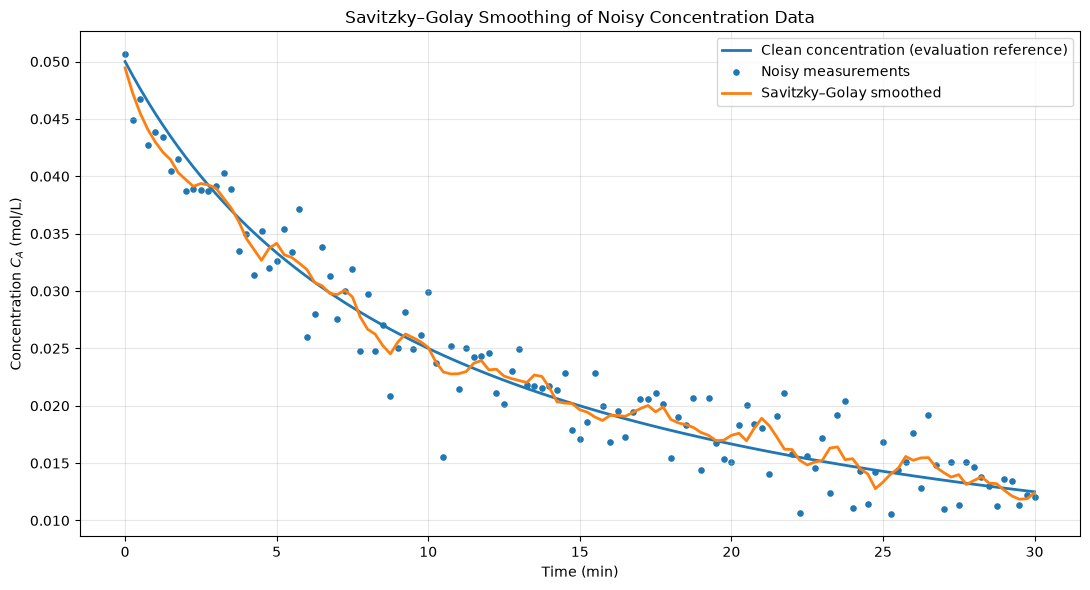

In [16]:
plt.figure(figsize=(11, 6))

plt.plot(
    sample["time_min"],
    sample["CA_true"],
    label="Clean concentration (evaluation reference)",
    linewidth=2
)
plt.scatter(
    sample["time_min"],
    sample["CA_observed"],
    label="Noisy measurements",
    s=14
)
plt.plot(
    sample["time_min"],
    sample["CA_smooth"],
    label="Savitzky–Golay smoothed",
    linewidth=2
)

plt.xlabel("Time (min)")
plt.ylabel("Concentration $C_A$ (mol/L)")
plt.title("Savitzky–Golay Smoothing of Noisy Concentration Data")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

### 13.5 Compare Raw and Smoothed Rate Estimates

The exact rate is used only as an evaluation reference. It is not used by either preprocessing method.

In [17]:
rate_evaluation = []

for method in ["rate_raw", "rate_sg"]:
    error = sample[method].to_numpy() - sample["rate_true"].to_numpy()
    rate_evaluation.append({
        "Method": method,
        "RMSE": np.sqrt(np.mean(error**2)),
        "MAE": np.mean(np.abs(error))
    })

rate_evaluation_df = pd.DataFrame(rate_evaluation)
display(rate_evaluation_df)

,Method,RMSE,MAE
0,rate_raw,0.007981,0.005751
1,rate_sg,0.002608,0.002080


## 14. PySR on Raw and Savitzky–Golay Processed Data

Two models are trained on the same noisy trajectory:

- **Raw model:** observed concentration as input and raw numerical derivative as target.
- **Savitzky–Golay model:** smoothed concentration as input and the derivative estimated by the Savitzky–Golay filter as target.

Neither model receives clean concentrations or exact rates during training.

In [18]:
X_raw = sample["CA_observed"].to_numpy(dtype=float).reshape(-1, 1)
y_raw = sample["rate_raw"].to_numpy(dtype=float)

X_sg = sample["CA_smooth"].to_numpy(dtype=float).reshape(-1, 1)
y_sg = sample["rate_sg"].to_numpy(dtype=float)

raw_model = create_pysr_model(verbosity=0)
raw_model.fit(X_raw, y_raw)

sg_model = create_pysr_model(verbosity=0)
sg_model.fit(X_sg, y_sg)

PySRRegressor.equations_ = [
	   pick     score                                           equation  \
	0        0.000000                                       0.0012705296   
	1  >>>>  0.095734                                     x0 ^ 1.7742226   
	2        0.008430                              (x0 + x0) ^ 2.2460263   
	3        0.003746                        ((x0 * x0) * x0) * 58.79654   
	4        0.000716         (((x0 * 46.41791) + 0.48478997) * x0) * x0   
	5        0.002586   ((((x0 * x0) * 737.6311) + 1.1337068) * x0) * x0   
	6        0.000011  x0 * (x0 * ((((x0 * 1426.9609) * x0) * 0.53162...   
	7        0.001250  ((x0 + (0.06095915 / ((0.080934666 - x0) * 0.0...   
	8        0.002856  x0 * (((-0.03558363 / (x0 - ((x0 * x0) - (x0 -...   
	
	       loss  complexity  
	0  0.000008           1  
	1  0.000007           3  
	2  0.000007           5  
	3  0.000007           7  
	4  0.000007           9  
	5  0.000007          11  
	6  0.000007          13  
	7  0.000007          1

### 14.1 Inspect the Discovered Equation Libraries

In [19]:
print("Raw-data PySR equations")
display(raw_model.equations_)

print("Savitzky–Golay PySR equations")
display(sg_model.equations_)

Raw-data PySR equations


,complexity,loss,equation,score,sympy_format,lambda_format
0,1,0.000067,0.0015160055,0.000000,0.00151600550000000,PySRFunction(X=>0.00151600550000000)
1,3,0.000064,x0 ^ 1.7005388,0.024246,x0**1.7005388,PySRFunction(X=>x0**1.7005388)
2,5,0.000063,(2.264985 * x0) ^ 2.264985,0.005940,(2.264985*x0)**2.264985,PySRFunction(X=>(2.264985*x0)**2.264985)
3,7,0.000059,(x0 * -0.0021642784) / (x0 + -0.055950683),0.034200,x0*(-0.0021642784)/(x0 - 0.055950683),PySRFunction(X=>x0*(-0.0021642784)/(x0 - 0.055...
4,9,0.000058,((x0 * -0.057160474) / (-0.057160474 + x0)) * x0,0.005011,x0*(-0.057160474)*x0/(x0 - 0.057160474),PySRFunction(X=>x0*(-0.057160474)*x0/(x0 - 0.0...
5,11,0.000056,((x0 * 0.10079997) * (x0 / (x0 + -0.051140763)...,0.019874,x0*0.10079997*x0*(-0.084641874)/(x0 - 0.051140...,PySRFunction(X=>x0*0.10079997*x0*(-0.084641874...
6,13,0.000056,((x0 * -0.67892885) * ((x0 / (x0 + -0.05114076...,0.000938,x0*(-0.67892885)*x0*(-0.13542233)*(-0.08464187...,PySRFunction(X=>x0*(-0.67892885)*x0*(-0.135422...


Savitzky–Golay PySR equations


,complexity,loss,equation,score,sympy_format,lambda_format
0,1,0.000008,0.0012705296,0.000000,0.00127052960000000,PySRFunction(X=>0.00127052960000000)
1,3,0.000007,x0 ^ 1.7742226,0.095734,x0**1.7742226,PySRFunction(X=>x0**1.7742226)
2,5,0.000007,(x0 + x0) ^ 2.2460263,0.008430,(x0 + x0)**2.2460263,PySRFunction(X=>(x0 + x0)**2.2460263)
3,7,0.000007,((x0 * x0) * x0) * 58.79654,0.003746,x0*x0*x0*58.79654,PySRFunction(X=>x0*x0*x0*58.79654)
4,9,0.000007,(((x0 * 46.41791) + 0.48478997) * x0) * x0,0.000716,x0*x0*(x0*46.41791 + 0.48478997),PySRFunction(X=>x0*x0*(x0*46.41791 + 0.48478997))
5,11,0.000007,((((x0 * x0) * 737.6311) + 1.1337068) * x0) * x0,0.002586,x0*x0*(x0*x0*737.6311 + 1.1337068),PySRFunction(X=>x0*x0*(x0*x0*737.6311 + 1.1337...
6,13,0.000007,x0 * (x0 * ((((x0 * 1426.9609) * x0) * 0.53162...,0.000011,x0*x0*(x0*1426.9609*x0*0.5316224 + 1.1062336),PySRFunction(X=>x0*x0*(x0*1426.9609*x0*0.53162...
7,15,0.000007,((x0 + (0.06095915 / ((0.080934666 - x0) * 0.0...,0.001250,(x0 + 0.06095915/(((0.080934666 - x0)*0.061401...,PySRFunction(X=>(x0 + 0.06095915/(((0.08093466...
8,17,0.000007,x0 * (((-0.03558363 / (x0 - ((x0 * x0) - (x0 -...,0.002856,x0*(-0.03558363)*x0/(x0 - (x0*x0 - (x0 - 1*0.1...,PySRFunction(X=>x0*(-0.03558363)*x0/(x0 - (x0*...


## 15. Simplify the Noisy-Data Equation Libraries

The simplifier is fitted using each model's noisy input-output pairs. The exact rate and clean concentration are reserved for evaluation.

In [20]:
raw_best, raw_simplification_summary, raw_candidate_tables = simplify_pysr_library(
    raw_model,
    X_raw.reshape(-1),
    y_raw
)

sg_best, sg_simplification_summary, sg_candidate_tables = simplify_pysr_library(
    sg_model,
    X_sg.reshape(-1),
    y_sg
)

print("Raw-data simplification candidates")
display(raw_simplification_summary)
print("Savitzky–Golay simplification candidates")
display(sg_simplification_summary)

print("Selected raw-data equation:")
print(raw_best["Simplified equation"])
print("Selected Savitzky–Golay equation:")
print(sg_best["Simplified equation"])

Raw-data simplification candidates


,Source equation,Source complexity,Simplified equation,Terms,Complexity,RSS,BIC,Selection Score
0,x0**1.7005388,3,1.76543422897e+18*x0**15.1914410959,1,2,0.006792,-1174.740406,-1165.148825
1,(2.264985*x0)**2.264985,5,1.74190146071e+18*x0**15.1869640749,1,2,0.006792,-1174.740406,-1165.148825
2,0.00151600550000000,1,0.00151578634775,1,0,0.008067,-1158.708248,-1158.708248
3,x0*(-0.0021642784)/(x0 - 0.055950683),7,0.00151578634775,1,0,0.008067,-1158.708248,-1158.708248
4,x0*(-0.057160474)*x0/(x0 - 0.057160474),9,0.0816608102077*x0,1,1,0.007838,-1162.199784,-1157.403993
5,x0*0.10079997*x0*(-0.084641874)/(x0 - 0.051140...,11,0.0816608102077*x0,1,1,0.007838,-1162.199784,-1157.403993
6,x0*(-0.67892885)*x0*(-0.13542233)*(-0.08464187...,13,0.0816608102077*x0,1,1,0.007838,-1162.199784,-1157.403993


Savitzky–Golay simplification candidates


,Source equation,Source complexity,Simplified equation,Terms,Complexity,RSS,BIC,Selection Score
0,x0*x0*x0*58.79654,7,58.8032918561*x0**3,1,2,0.000813,-1436.327851,-1426.736270
1,x0*x0*(x0*46.41791 + 0.48478997),9,58.8032918561*x0**3,1,2,0.000813,-1436.327851,-1426.736270
2,(x0 + 0.06095915/(((0.080934666 - x0)*0.061401...,15,58.8032918561*x0**3,1,2,0.000813,-1436.327851,-1426.736270
3,x0*x0*(x0*x0*737.6311 + 1.1337068),11,1413.92908739*x0**4,1,2,0.000822,-1434.994231,-1425.402650
4,x0*x0*(x0*1426.9609*x0*0.5316224 + 1.1062336),13,1413.92908739*x0**4,1,2,0.000822,-1434.994231,-1425.402650
5,x0*(-0.03558363)*x0/(x0 - (x0*x0 - (x0 - 1*0.1...,17,2.19576875693*x0**2,1,2,0.000825,-1434.658560,-1425.066979
6,x0**1.7742226,3,36.7320556827*x0**2.85420864478,1,2,0.000813,-1431.564732,-1421.973151
7,(x0 + x0)**2.2460263,5,36.7142576492*x0**2.85405919978,1,2,0.000813,-1431.564732,-1421.973150
8,0.00127052960000000,1,0.00127056082117,1,0,0.001009,-1410.213528,-1410.213528


Selected raw-data equation:
1.76543422897e+18*x0**15.1914410959
Selected Savitzky–Golay equation:
58.8032918561*x0**3


## 16. Evaluate the Noisy-Data Equations Against Ground Truth

The clean concentration and exact rate are used only to evaluate the equations learned from noisy data. This is a retrospective evaluation on the simulated trajectory; it is not a real-world selection procedure.

In [21]:
X_eval = sample["CA_true"].to_numpy(dtype=float)
y_eval = sample["rate_true"].to_numpy(dtype=float)

raw_predictions = predict_expression(
    raw_best["Simplified equation"], X_eval
)
sg_predictions = predict_expression(
    sg_best["Simplified equation"], X_eval
)

noisy_equation_comparison = pd.DataFrame([
    {
        "Method": "Raw PySR + Simplifier",
        "RMSE": np.sqrt(mean_squared_error(y_eval, raw_predictions)),
        "MAE": mean_absolute_error(y_eval, raw_predictions)
    },
    {
        "Method": "Savitzky–Golay + PySR + Simplifier",
        "RMSE": np.sqrt(mean_squared_error(y_eval, sg_predictions)),
        "MAE": mean_absolute_error(y_eval, sg_predictions)
    }
])

display(noisy_equation_comparison)

,Method,RMSE,MAE
0,Raw PySR + Simplifier,0.003152,0.001435
1,Savitzky–Golay + PySR + Simplifier,0.000503,0.000360


## 17. Evaluate the Full PySR Equation Libraries

Every equation in each PySR library is evaluated against the clean reference trajectory. This retrospective comparison shows whether a candidate with better ground-truth agreement exists in the library than the equation selected using noisy training data. The clean reference must not be used for model selection in an actual experimental workflow.

In [22]:
def evaluate_pysr_candidates(model, X_eval, y_eval):
    evaluation_results = []

    for _, row in model.equations_.iterrows():
        predictions = predict_expression(row["sympy_format"], X_eval)
        evaluation_results.append({
            "Equation": row["sympy_format"],
            "Complexity": row["complexity"],
            "PySR Training Loss": row["loss"],
            "Evaluation RMSE": np.sqrt(mean_squared_error(y_eval, predictions)),
            "Evaluation MAE": mean_absolute_error(y_eval, predictions)
        })

    return pd.DataFrame(evaluation_results).sort_values(
        ["Evaluation RMSE", "Complexity"]
    ).reset_index(drop=True)


raw_candidates_eval = evaluate_pysr_candidates(raw_model, X_eval, y_eval)
sg_candidates_eval = evaluate_pysr_candidates(sg_model, X_eval, y_eval)

print("Raw-data PySR candidate evaluation")
display(raw_candidates_eval)

print("Savitzky–Golay PySR candidate evaluation")
display(sg_candidates_eval)

Raw-data PySR candidate evaluation


,Equation,Complexity,PySR Training Loss,Evaluation RMSE,Evaluation MAE
0,(2.264985*x0)**2.264985,5,0.000063,0.000583,0.000326
1,x0**1.7005388,3,0.000064,0.000616,0.000564
2,0.00151600550000000,1,0.000067,0.001136,0.000951
3,x0*(-0.67892885)*x0*(-0.13542233)*(-0.08464187...,13,0.000056,0.001526,0.000984
4,x0*0.10079997*x0*(-0.084641874)/(x0 - 0.051140...,11,0.000056,0.001628,0.000980
5,x0*(-0.0021642784)/(x0 - 0.055950683),7,0.000059,0.002045,0.000976
6,x0*(-0.057160474)*x0/(x0 - 0.057160474),9,0.000058,0.002250,0.000775


Savitzky–Golay PySR candidate evaluation


,Equation,Complexity,PySR Training Loss,Evaluation RMSE,Evaluation MAE
0,x0**1.7742226,3,0.000007,0.000150,0.000145
1,(x0 + x0)**2.2460263,5,0.000007,0.000152,0.000100
2,x0*x0*(x0*46.41791 + 0.48478997),9,0.000007,0.000423,0.000280
3,x0*x0*(x0*x0*737.6311 + 1.1337068),11,0.000007,0.000468,0.000286
4,x0*x0*(x0*1426.9609*x0*0.5316224 + 1.1062336),13,0.000007,0.000481,0.000295
5,x0*x0*x0*58.79654,7,0.000007,0.000503,0.000360
6,(x0 + 0.06095915/(((0.080934666 - x0)*0.061401...,15,0.000007,0.000508,0.000260
7,x0*(-0.03558363)*x0/(x0 - (x0*x0 - (x0 - 1*0.1...,17,0.000007,0.000718,0.000417
8,0.00127052960000000,1,0.000008,0.001107,0.000853


## 18 — Systematic Evaluation of Noise Reduction

### 18.1 — Evaluate rate estimation across all experiments

In [23]:
from scipy.signal import savgol_filter

SG_WINDOW = 11
SG_POLYORDER = 3


def evaluate_rate_estimation(group, window=11, polyorder=3):

    group = group.sort_values("time_min")

    time = group["time_min"].values
    CA_observed = group["CA_observed"].values
    CA_true = group["CA_true"].values

    dt = np.mean(np.diff(time))

    # Raw numerical differentiation
    rate_raw = -np.gradient(
        CA_observed, time, edge_order=2
    )

    # Savitzky-Golay differentiation
    rate_sg = -savgol_filter(
        CA_observed,
        window_length=window,
        polyorder=polyorder,
        deriv=1,
        delta=dt
    )

    reaction = group["reaction"].iloc[0]

    params = parameters_df[
        parameters_df["reaction"] == reaction
    ].iloc[0].to_dict()

    # Theoretical rate used only for evaluation
    rate_true = np.array([
        calculate_rate(c, reaction, params)
        for c in CA_true
    ])

    # Exclude filter boundary observations
    half = window // 2
    indices = np.arange(len(group))

    valid = (
        (indices >= half) &
        (indices < len(group) - half)
    )

    # Exclude zero-order observations near depletion
    if reaction == "Zero_Order":

        active_indices = np.where(CA_true > 0)[0]

        if len(active_indices) == 0:
            return None

        last_active = active_indices[-1]

        valid &= indices <= last_active - half

    # Exclude invalid numerical values
    valid &= np.isfinite(rate_raw)
    valid &= np.isfinite(rate_sg)
    valid &= np.isfinite(rate_true)

    raw_error = rate_raw[valid] - rate_true[valid]
    sg_error = rate_sg[valid] - rate_true[valid]

    raw_rmse = np.sqrt(np.mean(raw_error**2))
    sg_rmse = np.sqrt(np.mean(sg_error**2))

    return {
        "Reaction": reaction,
        "Noise": group["noise_level"].iloc[0],
        "Replicate": group["replicate"].iloc[0],
        "Observations": valid.sum(),
        "Raw_RMSE": raw_rmse,
        "SG_RMSE": sg_rmse,
        "Raw_MAE": np.mean(np.abs(raw_error)),
        "SG_MAE": np.mean(np.abs(sg_error)),
        "RMSE_Improvement_%": (
            100 * (raw_rmse - sg_rmse) / raw_rmse
            if raw_rmse > 0 else 0
        )
    }


# Select noisy experiments
df_noisy = df[df["noise_level"] > 0].copy()

results = []

for _, group in df_noisy.groupby(
    ["reaction", "noise_level", "replicate"]
):

    result = evaluate_rate_estimation(
        group,
        window=SG_WINDOW,
        polyorder=SG_POLYORDER
    )

    if result is not None:
        results.append(result)


rate_metrics_df = pd.DataFrame(results)

display(rate_metrics_df)

,Reaction,Noise,Replicate,Observations,Raw_RMSE,SG_RMSE,Raw_MAE,SG_MAE,RMSE_Improvement_%
0,First_Order,0.01,1,111,0.001282,0.000490,0.000998,0.000387,61.818657
1,First_Order,0.01,2,111,0.001476,0.000537,0.001140,0.000434,63.605543
2,First_Order,0.01,3,111,0.001560,0.000507,0.001271,0.000423,67.498201
3,First_Order,0.01,4,111,0.001381,0.000411,0.001129,0.000320,70.244458
4,First_Order,0.01,5,111,0.001258,0.000454,0.001023,0.000356,63.949773
...,...,...,...,...,...,...,...,...,...
85,Zero_Order,0.05,1,30,0.008660,0.002889,0.007097,0.002379,66.635418
86,Zero_Order,0.05,2,30,0.006576,0.002964,0.004908,0.002547,54.919617
87,Zero_Order,0.05,3,30,0.007831,0.002535,0.006444,0.002081,67.631418
88,Zero_Order,0.05,4,30,0.007307,0.001949,0.006172,0.001571,73.329761


In [24]:
rate_summary = (
    rate_metrics_df
    .groupby(["Reaction", "Noise"])
    .agg({
        "Raw_RMSE": "mean",
        "SG_RMSE": "mean",
        "Raw_MAE": "mean",
        "SG_MAE": "mean",
        "RMSE_Improvement_%": "mean"
    })
    .reset_index()
)

display(rate_summary)

,Reaction,Noise,Raw_RMSE,SG_RMSE,Raw_MAE,SG_MAE,RMSE_Improvement_%
0,First_Order,0.01,0.001391,0.000480,0.001112,0.000384,65.423326
1,First_Order,0.03,0.004120,0.001500,0.003297,0.001234,63.371749
2,First_Order,0.05,0.007551,0.002620,0.006009,0.002134,65.245120
3,Fourth_Order,0.01,0.001422,0.000451,0.001174,0.000368,68.181817
4,Fourth_Order,0.03,0.004187,0.001501,0.003432,0.001222,64.321328
5,Fourth_Order,0.05,0.006915,0.002497,0.005497,0.002006,63.760884
6,Fractional_Order,0.01,0.001339,0.000458,0.001088,0.000366,65.908623
7,Fractional_Order,0.03,0.004216,0.001445,0.003350,0.001175,65.491768
8,Fractional_Order,0.05,0.007240,0.002597,0.005804,0.002096,64.083243
9,Saturation,0.01,0.001424,0.000516,0.001123,0.000419,63.392391


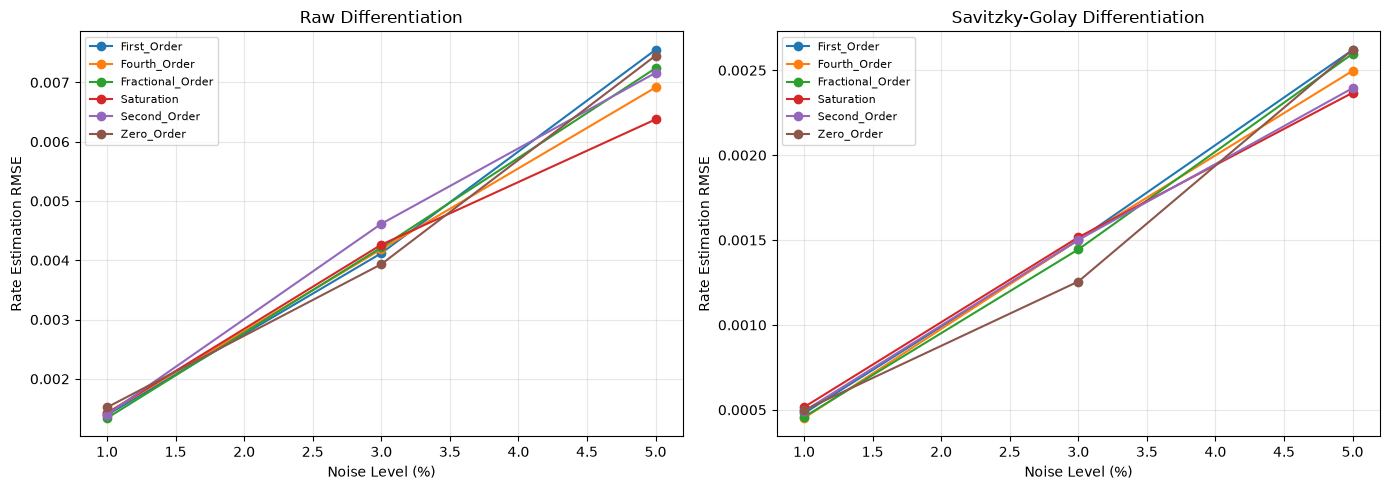

In [26]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

for reaction in rate_summary["Reaction"].unique():

    subset = rate_summary[
        rate_summary["Reaction"] == reaction
    ]

    axes[0].plot(
        subset["Noise"] * 100,
        subset["Raw_RMSE"],
        marker="o",
        label=reaction
    )

    axes[1].plot(
        subset["Noise"] * 100,
        subset["SG_RMSE"],
        marker="o",
        label=reaction
    )

axes[0].set_title("Raw Differentiation")
axes[1].set_title("Savitzky-Golay Differentiation")

for ax in axes:
    ax.set_xlabel("Noise Level (%)")
    ax.set_ylabel("Rate Estimation RMSE")
    ax.grid(alpha=0.3)
    ax.legend(fontsize=8)

plt.tight_layout()
plt.show()

## 19 — Systematic PySR Equation Recovery

In [27]:
def preprocess_trajectory(group, window=11, polyorder=3):

    group = group.sort_values("time_min").copy()

    time = group["time_min"].values
    CA = group["CA_observed"].values

    dt = np.mean(np.diff(time))

    # Raw numerical differentiation
    rate_raw = -np.gradient(
        CA, time, edge_order=2
    )

    # Savitzky-Golay smoothing
    CA_smooth = savgol_filter(
        CA,
        window_length=window,
        polyorder=polyorder
    )

    # Savitzky-Golay differentiation
    rate_sg = -savgol_filter(
        CA,
        window_length=window,
        polyorder=polyorder,
        deriv=1,
        delta=dt
    )

    half = window // 2
    indices = np.arange(len(group))

    group["CA_smooth"] = CA_smooth
    group["rate_raw"] = rate_raw
    group["rate_sg"] = rate_sg

    # Flag boundary observations for later exclusion
    group["valid_interior"] = (
        (indices >= half) &
        (indices < len(group) - half)
    )

    return group

In [30]:
observed_data = df.loc[
    df["noise_level"] > 0,
    [
        "reaction",
        "time_min",
        "noise_level",
        "replicate",
        "CA_observed"
    ]
].copy()

processed_groups = []

group_columns = ["reaction", "noise_level", "replicate"]

for (reaction, noise, replicate), group in observed_data.groupby(
    group_columns,
    sort=False
):

    processed = preprocess_trajectory(
        group,
        window=SG_WINDOW,
        polyorder=SG_POLYORDER
    )

    # Restore experimental identifiers
    processed["reaction"] = reaction
    processed["noise_level"] = noise
    processed["replicate"] = replicate

    processed_groups.append(processed)

df_processed = pd.concat(
    processed_groups,
    ignore_index=True
)

# Arrange columns
df_processed = df_processed[
    [
        "reaction",
        "time_min",
        "noise_level",
        "replicate",
        "CA_observed",
        "CA_smooth",
        "rate_raw",
        "rate_sg",
        "valid_interior"
    ]
]

display(df_processed.head())

,reaction,time_min,noise_level,replicate,CA_observed,CA_smooth,rate_raw,rate_sg,valid_interior
0,First_Order,0.00,0.01,1,0.049883,0.049533,0.013287,0.005289,False
1,First_Order,0.25,0.01,1,0.047578,0.048259,0.005153,0.004908,False
2,First_Order,0.50,0.01,1,0.047306,0.047074,0.003414,0.004582,False
3,First_Order,0.75,0.01,1,0.045871,0.045964,0.004209,0.004313,False
4,First_Order,1.00,0.01,1,0.045202,0.044913,0.004065,0.004101,False


In [31]:
print("Processed dataset shape:", df_processed.shape)

print("\nReaction counts:")
print(df_processed["reaction"].value_counts())

print("\nNoise levels:")
print(df_processed["noise_level"].unique())

print("\nMissing values:")
print(df_processed.isnull().sum())

Processed dataset shape: (10890, 9)

Reaction counts:
reaction
First_Order         1815
Second_Order        1815
Fractional_Order    1815
Saturation          1815
Fourth_Order        1815
Zero_Order          1815
Name: count, dtype: int64

Noise levels:
[0.01 0.03 0.05]

Missing values:
reaction          0
time_min          0
noise_level       0
replicate         0
CA_observed       0
CA_smooth         0
rate_raw          0
rate_sg           0
valid_interior    0
dtype: int64


In [32]:
# Training and validation trajectories
train_data = df_processed[
    (df_processed["replicate"].isin([1, 2, 3, 4])) &
    (df_processed["valid_interior"])
].copy()

validation_data = df_processed[
    (df_processed["replicate"] == 5) &
    (df_processed["valid_interior"])
].copy()

print("Training observations:", len(train_data))
print("Validation observations:", len(validation_data))

print("\nTraining distribution:")
display(
    train_data.groupby(
        ["reaction", "noise_level"]
    ).size().unstack()
)

print("\nValidation distribution:")
display(
    validation_data.groupby(
        ["reaction", "noise_level"]
    ).size().unstack()
)

Training observations: 7992
Validation observations: 1998

Training distribution:


noise_level,0.01,0.03,0.05
reaction,,,
First_Order,444,444,444
Fourth_Order,444,444,444
Fractional_Order,444,444,444
Saturation,444,444,444
Second_Order,444,444,444
Zero_Order,444,444,444



Validation distribution:


noise_level,0.01,0.03,0.05
reaction,,,
First_Order,111,111,111
Fourth_Order,111,111,111
Fractional_Order,111,111,111
Saturation,111,111,111
Second_Order,111,111,111
Zero_Order,111,111,111


In [33]:
reaction = "Second_Order"
noise = 0.05

train_subset = train_data[
    (train_data["reaction"] == reaction) &
    (train_data["noise_level"] == noise)
]

val_subset = validation_data[
    (validation_data["reaction"] == reaction) &
    (validation_data["noise_level"] == noise)
]

# Raw training data
X_raw_train = train_subset[
    ["CA_observed"]
].values

y_raw_train = train_subset[
    "rate_raw"
].values

# SG training data
X_sg_train = train_subset[
    ["CA_smooth"]
].values

y_sg_train = train_subset[
    "rate_sg"
].values

print("Training shape:", X_raw_train.shape)
print("Validation trajectories:", val_subset["replicate"].nunique())

Training shape: (444, 1)
Validation trajectories: 1


In [34]:
def create_pysr_model():

    return PySRRegressor(
        niterations=100,
        populations=15,
        population_size=33,
        maxsize=20,

        binary_operators=[
            "+", "-", "*", "/", "^"
        ],

        constraints={
            "^": (-1, 1)
        },

        model_selection="best",
        verbosity=0
    )

In [35]:
raw_model_robust = create_pysr_model()

raw_model_robust.fit(
    X_raw_train,
    y_raw_train
)

print("Raw-data training completed.")

display(raw_model_robust.equations_)

Raw-data training completed.


,complexity,loss,equation,score,sympy_format,lambda_format
0,1,0.000053,0.0011722018,0.000000e+00,0.00117220180000000,PySRFunction(X=>0.00117220180000000)
1,3,0.000052,x0 ^ 1.8060089,6.443365e-03,x0**1.8060089,PySRFunction(X=>x0**1.8060089)
2,5,0.000052,(x0 ^ 1.8742574) * 1.2666221,1.070747e-05,x0**1.8742574*1.2666221,PySRFunction(X=>x0**1.8742574*1.2666221)
3,7,0.000052,((x0 * 1.8314834) * x0) + 0.000105577616,2.597595e-05,x0*1.8314834*x0 + 0.000105577616,PySRFunction(X=>x0*1.8314834*x0 + 0.000105577616)
4,9,0.000052,(((x0 * 2.5035317) - 0.035480812) * x0) + 0.00...,2.614087e-05,x0*(x0*2.5035317 - 1*0.035480812) + 0.00051395106,PySRFunction(X=>x0*(x0*2.5035317 - 1*0.0354808...
5,11,0.000052,((((x0 * -5.282007) * x0) - 0.005935386) * -5....,4.002550e-06,(x0*(-5.282007)*x0 - 1*0.005935386)*(-5.277823...,PySRFunction(X=>(x0*(-5.282007)*x0 - 1*0.00593...
6,15,0.000052,(((((x0 + (x0 * x0)) * -5.282007) * x0) - 0.00...,7.985902e-07,((x0 + x0*x0)*(-5.282007)*x0 - 1*0.005935386)*...,PySRFunction(X=>((x0 + x0*x0)*(-5.282007)*x0 -...


In [36]:
sg_model_robust = create_pysr_model()

sg_model_robust.fit(
    X_sg_train,
    y_sg_train
)

print("SG-data training completed.")

display(sg_model_robust.equations_)

SG-data training completed.


,complexity,loss,equation,score,sympy_format,lambda_format
0,1,0.000006,0.0011686079,0.000000,0.00116860790000000,PySRFunction(X=>0.00116860790000000)
1,3,0.000006,x0 ^ 1.7955536,0.066685,x0**1.7955536,PySRFunction(X=>x0**1.7955536)
2,5,0.000006,(x0 * 2.0347474) * x0,0.001208,x0*2.0347474*x0,PySRFunction(X=>x0*2.0347474*x0)
3,7,0.000006,(x0 * x0) / (0.5253541 - x0),0.000192,x0*x0/(0.5253541 - x0),PySRFunction(X=>x0*x0/(0.5253541 - x0))
4,9,0.000006,((x0 + 0.17702505) * (x0 * x0)) * 9.638199,0.000086,(x0 + 0.17702505)*x0*x0*9.638199,PySRFunction(X=>(x0 + 0.17702505)*x0*x0*9.638199)
5,15,0.000006,((x0 * (x0 ^ x0)) - x0) + (((x0 * x0) * 4.9311...,0.000132,x0*x0**x0 - x0 + x0*x0*4.931166 - 1*(-0.000301...,PySRFunction(X=>x0*x0**x0 - x0 + x0*x0*4.93116...


In [37]:
print("RAW DATA — CANDIDATE EQUATIONS")
display(raw_model_robust.equations_)

print("SAVITZKY-GOLAY — CANDIDATE EQUATIONS")
display(sg_model_robust.equations_)

RAW DATA — CANDIDATE EQUATIONS


,complexity,loss,equation,score,sympy_format,lambda_format
0,1,0.000053,0.0011722018,0.000000e+00,0.00117220180000000,PySRFunction(X=>0.00117220180000000)
1,3,0.000052,x0 ^ 1.8060089,6.443365e-03,x0**1.8060089,PySRFunction(X=>x0**1.8060089)
2,5,0.000052,(x0 ^ 1.8742574) * 1.2666221,1.070747e-05,x0**1.8742574*1.2666221,PySRFunction(X=>x0**1.8742574*1.2666221)
3,7,0.000052,((x0 * 1.8314834) * x0) + 0.000105577616,2.597595e-05,x0*1.8314834*x0 + 0.000105577616,PySRFunction(X=>x0*1.8314834*x0 + 0.000105577616)
4,9,0.000052,(((x0 * 2.5035317) - 0.035480812) * x0) + 0.00...,2.614087e-05,x0*(x0*2.5035317 - 1*0.035480812) + 0.00051395106,PySRFunction(X=>x0*(x0*2.5035317 - 1*0.0354808...
5,11,0.000052,((((x0 * -5.282007) * x0) - 0.005935386) * -5....,4.002550e-06,(x0*(-5.282007)*x0 - 1*0.005935386)*(-5.277823...,PySRFunction(X=>(x0*(-5.282007)*x0 - 1*0.00593...
6,15,0.000052,(((((x0 + (x0 * x0)) * -5.282007) * x0) - 0.00...,7.985902e-07,((x0 + x0*x0)*(-5.282007)*x0 - 1*0.005935386)*...,PySRFunction(X=>((x0 + x0*x0)*(-5.282007)*x0 -...


SAVITZKY-GOLAY — CANDIDATE EQUATIONS


,complexity,loss,equation,score,sympy_format,lambda_format
0,1,0.000006,0.0011686079,0.000000,0.00116860790000000,PySRFunction(X=>0.00116860790000000)
1,3,0.000006,x0 ^ 1.7955536,0.066685,x0**1.7955536,PySRFunction(X=>x0**1.7955536)
2,5,0.000006,(x0 * 2.0347474) * x0,0.001208,x0*2.0347474*x0,PySRFunction(X=>x0*2.0347474*x0)
3,7,0.000006,(x0 * x0) / (0.5253541 - x0),0.000192,x0*x0/(0.5253541 - x0),PySRFunction(X=>x0*x0/(0.5253541 - x0))
4,9,0.000006,((x0 + 0.17702505) * (x0 * x0)) * 9.638199,0.000086,(x0 + 0.17702505)*x0*x0*9.638199,PySRFunction(X=>(x0 + 0.17702505)*x0*x0*9.638199)
5,15,0.000006,((x0 * (x0 ^ x0)) - x0) + (((x0 * x0) * 4.9311...,0.000132,x0*x0**x0 - x0 + x0*x0*4.931166 - 1*(-0.000301...,PySRFunction(X=>x0*x0**x0 - x0 + x0*x0*4.93116...


In [38]:
val_subset = df_processed[
    (df_processed["reaction"] == "Second_Order") &
    (df_processed["noise_level"] == 0.05) &
    (df_processed["replicate"] == 5) &
    (df_processed["valid_interior"])
].copy()

X_raw_val = val_subset["CA_observed"].values
y_raw_val = val_subset["rate_raw"].values

X_sg_val = val_subset["CA_smooth"].values
y_sg_val = val_subset["rate_sg"].values

print("Validation observations:", len(val_subset))

Validation observations: 111


In [39]:
def evaluate_validation(model, X_val, y_val):

    equations = model.equations_

    results = []

    for _, row in equations.iterrows():

        expr = sp.sympify(row["sympy_format"])

        func = sp.lambdify(x0, expr, "numpy")

        try:
            predictions = np.asarray(
                func(X_val), dtype=float
            )

            predictions = np.broadcast_to(
                predictions, X_val.shape
            )

            if not np.all(np.isfinite(predictions)):
                continue

            rmse = np.sqrt(
                np.mean((y_val - predictions)**2)
            )

            results.append({
                "Equation": expr,
                "Complexity": row["complexity"],
                "Training Loss": row["loss"],
                "Validation RMSE": rmse
            })

        except Exception:
            continue

    return pd.DataFrame(results).sort_values(
        "Validation RMSE"
    ).reset_index(drop=True)

In [40]:
raw_validation_results = evaluate_validation(
    raw_model_robust,
    X_raw_val,
    y_raw_val
)

sg_validation_results = evaluate_validation(
    sg_model_robust,
    X_sg_val,
    y_sg_val
)

print("RAW MODEL VALIDATION")
display(raw_validation_results)

print("SG MODEL VALIDATION")
display(sg_validation_results)

RAW MODEL VALIDATION


,Equation,Complexity,Training Loss,Validation RMSE
0,x0*(x0*2.5035317 - 1*0.035480812) + 0.00051395106,9,0.000052,0.007094
1,x0*1.8314834*x0 + 0.000105577616,7,0.000052,0.007094
2,(x0*(-5.282007)*x0 - 1*0.005935386)*(-5.277823...,11,0.000052,0.007094
3,x0**1.8060089,3,0.000052,0.007094
4,((x0 + x0*x0)*(-5.282007)*x0 - 1*0.005935386)*...,15,0.000052,0.007095
5,x0**1.8742574*1.2666221,5,0.000052,0.007095
6,0.00117220180000000,1,0.000053,0.007127


SG MODEL VALIDATION


,Equation,Complexity,Training Loss,Validation RMSE
0,x0**1.7955536,3,0.000006,0.002510
1,x0*x0**x0 - x0 + x0*x0*4.931166 - 1*(-0.000301...,15,0.000006,0.002515
2,x0*2.0347474*x0,5,0.000006,0.002516
3,x0*x0/(0.5253541 - x0),7,0.000006,0.002518
4,(x0 + 0.17702505)*x0*x0*9.638199,9,0.000006,0.002521
5,0.00116860790000000,1,0.000006,0.002603


In [41]:
# Retrieve the true concentrations for validation replicate
true_validation = df[
    (df["reaction"] == "Second_Order") &
    (df["noise_level"] == 0.05) &
    (df["replicate"] == 5)
][["time_min", "CA_true"]]

val_eval = val_subset.merge(
    true_validation,
    on="time_min",
    how="inner",
    validate="one_to_one"
)

# Calculate theoretical rates
params = parameters_df[
    parameters_df["reaction"] == "Second_Order"
].iloc[0].to_dict()

val_eval["rate_true"] = [
    calculate_rate(ca, "Second_Order", params)
    for ca in val_eval["CA_true"]
]

X_true_val = val_eval["CA_true"].values
y_true_val = val_eval["rate_true"].values

print("Validation observations:", len(val_eval))

Validation observations: 111


In [42]:
def evaluate_candidates_against_truth(
    model, X_operational, y_estimated,
    X_true, y_true, method
):

    results = []

    for _, row in model.equations_.iterrows():

        expr = row["sympy_format"]
        func = sp.lambdify(x0, expr, "numpy")

        try:
            with np.errstate(all="ignore"):

                pred_operational = np.asarray(
                    func(X_operational), dtype=float
                )

                pred_true_input = np.asarray(
                    func(X_true), dtype=float
                )

            pred_operational = np.broadcast_to(
                pred_operational, X_true.shape
            )

            pred_true_input = np.broadcast_to(
                pred_true_input, X_true.shape
            )

            if not (
                np.all(np.isfinite(pred_operational)) and
                np.all(np.isfinite(pred_true_input))
            ):
                continue

            estimated_rmse = np.sqrt(
                np.mean((y_estimated - pred_operational)**2)
            )

            operational_rmse = np.sqrt(
                np.mean((y_true - pred_operational)**2)
            )

            equation_rmse = np.sqrt(
                np.mean((y_true - pred_true_input)**2)
            )

            results.append({
                "Method": method,
                "Equation": expr,
                "Complexity": row["complexity"],
                "Estimated_Rate_RMSE": estimated_rmse,
                "True_Rate_RMSE": operational_rmse,
                "Equation_RMSE": equation_rmse
            })

        except Exception:
            continue

    return pd.DataFrame(results).sort_values(
        "True_Rate_RMSE"
    ).reset_index(drop=True)

In [43]:
raw_truth_results = evaluate_candidates_against_truth(
    raw_model_robust,
    X_raw_val,
    y_raw_val,
    X_true_val,
    y_true_val,
    "Raw"
)

sg_truth_results = evaluate_candidates_against_truth(
    sg_model_robust,
    X_sg_val,
    y_sg_val,
    X_true_val,
    y_true_val,
    "Savitzky-Golay"
)

print("RAW MODEL")
display(raw_truth_results)

print("SG MODEL")
display(sg_truth_results)

RAW MODEL


,Method,Equation,Complexity,Estimated_Rate_RMSE,True_Rate_RMSE,Equation_RMSE
0,Raw,x0**1.8060089,3,0.007094,0.000236,0.000088
1,Raw,x0*1.8314834*x0 + 0.000105577616,7,0.007094,0.000238,0.000075
2,Raw,x0**1.8742574*1.2666221,5,0.007095,0.000239,0.000063
3,Raw,(x0*(-5.282007)*x0 - 1*0.005935386)*(-5.277823...,11,0.007094,0.000245,0.000102
4,Raw,x0*(x0*2.5035317 - 1*0.035480812) + 0.00051395106,9,0.007094,0.000247,0.000083
5,Raw,((x0 + x0*x0)*(-5.282007)*x0 - 1*0.005935386)*...,15,0.007095,0.000257,0.000090
6,Raw,0.00117220180000000,1,0.007127,0.000891,0.000891


SG MODEL


,Method,Equation,Complexity,Estimated_Rate_RMSE,True_Rate_RMSE,Equation_RMSE
0,Savitzky-Golay,x0**1.7955536,3,0.002510,0.000150,0.000084
1,Savitzky-Golay,x0*2.0347474*x0,5,0.002516,0.000155,0.000025
2,Savitzky-Golay,x0*x0/(0.5253541 - x0),7,0.002518,0.000161,0.000036
3,Savitzky-Golay,x0*x0**x0 - x0 + x0*x0*4.931166 - 1*(-0.000301...,15,0.002515,0.000163,0.000079
4,Savitzky-Golay,(x0 + 0.17702505)*x0*x0*9.638199,9,0.002521,0.000173,0.000062
5,Savitzky-Golay,0.00116860790000000,1,0.002603,0.000891,0.000891


In [44]:
# Extract candidate equations from SG-PySR
candidate_equations = sg_model_robust.equations_.copy()

simplification_results = []

for _, row in candidate_equations.iterrows():

    equation = row["sympy_format"]

    # Simplify using training data only
    best, candidates = automatic_simplify(
        equation,
        X_sg_train.flatten(),
        y_sg_train
    )

    simplification_results.append({
        "Original Equation": equation,
        "Simplified Equation": best["equation"],
        "Original Complexity": row["complexity"],
        "Simplified Complexity": sp.count_ops(
            best["equation"]
        ),
        "Training RSS": best["RSS"],
        "Training BIC": best["BIC"]
    })

simplification_results_df = pd.DataFrame(
    simplification_results
)

display(simplification_results_df)

,Original Equation,Simplified Equation,Original Complexity,Simplified Complexity,Training RSS,Training BIC
0,0.00116860790000000,0.00116836482427,1,0,0.002867,-5299.845757
1,x0**1.7955536,3.03807338047*x0**2.11766214189,3,2,0.002502,-5354.192024
2,x0*2.0347474*x0,2.03471012721*x0**2,5,2,0.002503,-5360.134845
3,x0*x0/(0.5253541 - x0),2.03471012721*x0**2,7,2,0.002503,-5360.134845
4,(x0 + 0.17702505)*x0*x0*9.638199,2.03471012721*x0**2,9,2,0.002503,-5360.134845
5,x0*x0**x0 - x0 + x0*x0*4.931166 - 1*(-0.000301...,2.03471012721*x0**2,15,2,0.002503,-5360.134845


In [45]:
simplification_validation = []

for _, row in simplification_results_df.iterrows():

    original_expr = sp.sympify(row["Original Equation"])
    simplified_expr = sp.sympify(row["Simplified Equation"])

    original_func = sp.lambdify(x0, original_expr, "numpy")
    simplified_func = sp.lambdify(x0, simplified_expr, "numpy")

    try:
        # Predictions against SG-processed validation data
        original_pred = np.broadcast_to(
            original_func(X_sg_val), X_sg_val.shape
        )

        simplified_pred = np.broadcast_to(
            simplified_func(X_sg_val), X_sg_val.shape
        )

        # Predictions at true validation concentrations
        original_true_pred = np.broadcast_to(
            original_func(X_true_val), X_true_val.shape
        )

        simplified_true_pred = np.broadcast_to(
            simplified_func(X_true_val), X_true_val.shape
        )

        original_val_rmse = np.sqrt(
            np.mean((y_sg_val - original_pred)**2)
        )

        simplified_val_rmse = np.sqrt(
            np.mean((y_sg_val - simplified_pred)**2)
        )

        original_equation_rmse = np.sqrt(
            np.mean((y_true_val - original_true_pred)**2)
        )

        simplified_equation_rmse = np.sqrt(
            np.mean((y_true_val - simplified_true_pred)**2)
        )

        simplification_validation.append({
            "Simplified Equation": simplified_expr,
            "Complexity": sp.count_ops(simplified_expr),
            "Original Validation RMSE": original_val_rmse,
            "Simplified Validation RMSE": simplified_val_rmse,
            "Original Equation RMSE": original_equation_rmse,
            "Simplified Equation RMSE": simplified_equation_rmse
        })

    except Exception as e:
        print("Candidate evaluation failed:", e)

validation_df = pd.DataFrame(simplification_validation)

display(validation_df)

,Simplified Equation,Complexity,Original Validation RMSE,Simplified Validation RMSE,Original Equation RMSE,Simplified Equation RMSE
0,0.00116836482427,0,0.002603,0.002603,0.000891,0.000891
1,3.03807338047*x0**2.11766214189,2,0.002510,0.002520,0.000084,0.000053
2,2.03471012721*x0**2,2,0.002516,0.002516,0.000025,0.000025
3,2.03471012721*x0**2,2,0.002518,0.002516,0.000036,0.000025
4,2.03471012721*x0**2,2,0.002521,0.002516,0.000062,0.000025
5,2.03471012721*x0**2,2,0.002515,0.002516,0.000079,0.000025


In [46]:
selection_df = validation_df.copy()

selection_df = selection_df.sort_values(
    ["Simplified Validation RMSE", "Complexity"]
)

selection_df = selection_df.drop_duplicates(
    subset=["Simplified Equation"]
)

selected_candidate = selection_df.iloc[0]

print("Selected equation:")
print(selected_candidate["Simplified Equation"])

print("\nValidation RMSE:")
print(selected_candidate["Simplified Validation RMSE"])

print("\nComplexity:")
print(selected_candidate["Complexity"])

Selected equation:
2.03471012721*x0**2

Validation RMSE:
0.002516147367712718

Complexity:
2


In [47]:
reaction = "First_Order"
noise = 0.05

train_subset = train_data[
    (train_data["reaction"] == reaction) &
    (train_data["noise_level"] == noise)
].copy()

val_subset = validation_data[
    (validation_data["reaction"] == reaction) &
    (validation_data["noise_level"] == noise)
].copy()

# Raw training data
X_raw_train = train_subset[
    ["CA_observed"]
].values

y_raw_train = train_subset[
    "rate_raw"
].values

# Savitzky-Golay training data
X_sg_train = train_subset[
    ["CA_smooth"]
].values

y_sg_train = train_subset[
    "rate_sg"
].values

# Validation data
X_raw_val = val_subset["CA_observed"].values
y_raw_val = val_subset["rate_raw"].values

X_sg_val = val_subset["CA_smooth"].values
y_sg_val = val_subset["rate_sg"].values

print("Raw training:", X_raw_train.shape)
print("SG training:", X_sg_train.shape)
print("Validation:", X_raw_val.shape)

Raw training: (444, 1)
SG training: (444, 1)
Validation: (111,)


In [48]:
raw_model_first = create_pysr_model()

raw_model_first.fit(
    X_raw_train,
    y_raw_train
)

print("Raw-data training completed.")

display(raw_model_first.equations_)

Raw-data training completed.


,complexity,loss,equation,score,sympy_format,lambda_format
0,1,0.000058,0.0013841123,0.000000,0.00138411230000000,PySRFunction(X=>0.00138411230000000)
1,3,0.000057,x0 * 0.0955835,0.012057,x0*0.0955835,PySRFunction(X=>x0*0.0955835)
2,5,0.000057,(x0 * 0.10215164) - 0.00015816712,0.000081,x0*0.10215164 - 1*0.00015816712,PySRFunction(X=>x0*0.10215164 - 1*0.00015816712)
3,7,0.000057,((x0 * x0) ^ 0.6201151) * 0.22650146,0.000310,(x0*x0)**0.6201151*0.22650146,PySRFunction(X=>(x0*x0)**0.6201151*0.22650146)
4,11,0.000057,(((0.27061397 / x0) * -9.467283e-7) + x0) - (x...,0.000142,-0.9018323*x0 + x0 + 0.27061397*(-9.467283e-7)/x0,PySRFunction(X=>-0.9018323*x0 + x0 + 0.2706139...
5,13,0.000057,((((x0 / x0) / x0) * -9.467283e-7) + x0) - (x0...,0.000791,-0.9018323*x0 + x0 + x0*(-9.467283e-7)/(x0*x0),PySRFunction(X=>-0.9018323*x0 + x0 + x0*(-9.46...
6,19,0.000056,((0.14542319 - (((x0 + x0) * x0) / (x0 * (x0 -...,0.001151,(0.14542319 - x0*(x0 + x0)/(x0*(x0 - 1*(-0.001...,PySRFunction(X=>(0.14542319 - x0*(x0 + x0)/(x0...


In [49]:
print("SAVITZKY-GOLAY MODEL")
display(sg_model_first.equations_)

SAVITZKY-GOLAY MODEL


NameError: name 'sg_model_first' is not defined